In [4]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\gayat\AppData\Local\Programs\Python\Python311\python.exe
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [5]:
%pip install numpy pandas matplotlib seaborn scikit-learn xgboost shap joblib

^C
Note: you may need to restart the kernel to use updated packages.


  Using cached pandas-3.1.0-cp311-cp311-win_amd64.whl.metadata (18 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
  Using cached shap-0.51.0-cp311-cp311-win_amd64.whl.metadata (26 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached numba-0.68.1-cp311-cp311-win_amd64.whl.metadata (2.9 kB)
  Using cached llvmlite-0.50.0-cp311-cp311-win_amd64.whl.metadata (5.0 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached pandas-3.1.0-cp311-cp311-win_


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, precision_recall_curve
from xgboost import XGBClassifier
import joblib

In [9]:
# PaySim has ~6.3 million rows, too heavy for a 24-hour hackathon
df = pd.read_csv("../data/UPIfrauddetection.csv")  # use your actual filename

print(df.shape)
print(df["isFraud"].value_counts())   # you'll see fraud is tiny (~0.1%)

# Keep ALL fraud rows + a random 100k of the legit ones
fraud = df[df["isFraud"] == 1]
legit = df[df["isFraud"] == 0].sample(n=100_000, random_state=42)

# Combine and shuffle so fraud rows aren't all grouped together
df = pd.concat([fraud, legit]).sample(frac=1, random_state=42).reset_index(drop=True)

(6362620, 11)
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [10]:
# 'step' = hours since the simulation started, so step % 24 gives hour of day
df["hour"] = df["step"] % 24

# Balance mismatch features: if the money doesn't add up, that's suspicious
df["errorOrig"] = df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
df["errorDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

# Turn the 'type' column (TRANSFER, CASH_OUT, ...) into 0/1 columns
df = pd.get_dummies(df, columns=["type"])

# Drop columns the model shouldn't use (account names are just IDs)
X = df.drop(columns=["isFraud", "isFlaggedFraud", "nameOrig", "nameDest", "step"])
y = df["isFraud"]

# stratify=y keeps the same fraud ratio in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [11]:
# Fraud is rare, so the model could just say "legit" every time and look good.
# scale_pos_weight tells XGBoost to treat each fraud row as more important.
# Rule of thumb: (number of legit rows) / (number of fraud rows)
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Legit-to-fraud ratio:", round(ratio, 1))

xgb = XGBClassifier(
    n_estimators=200,        # number of trees built one after another
    max_depth=5,             # how deep each tree can go (deeper = more complex)
    learning_rate=0.1,       # how much each new tree corrects the previous ones
    scale_pos_weight=ratio,  # handles the imbalance
    eval_metric="aucpr",     # area under the precision-recall curve, good for rare fraud
    random_state=42,
)
xgb.fit(X_train, y_train)

# predict_proba gives [P(legit), P(fraud)] for each row; we want column 1
xgb_probs = xgb.predict_proba(X_test)[:, 1]
xgb_preds = (xgb_probs >= 0.5).astype(int)   # 0.5 is the default cut-off

print(classification_report(y_test, xgb_preds, target_names=["Legit", "Fraud"]))

Legit-to-fraud ratio: 12.2
              precision    recall  f1-score   support

       Legit       1.00      1.00      1.00     20000
       Fraud       1.00      1.00      1.00      1643

    accuracy                           1.00     21643
   macro avg       1.00      1.00      1.00     21643
weighted avg       1.00      1.00      1.00     21643



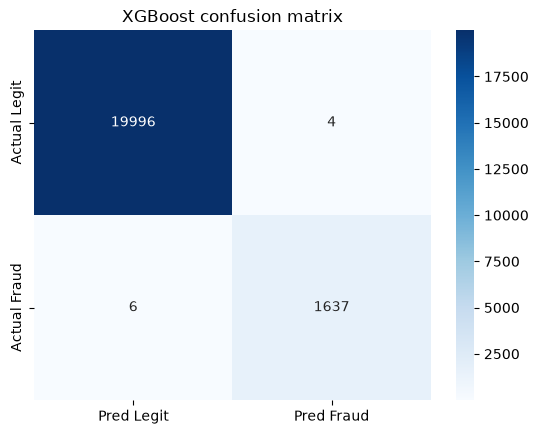

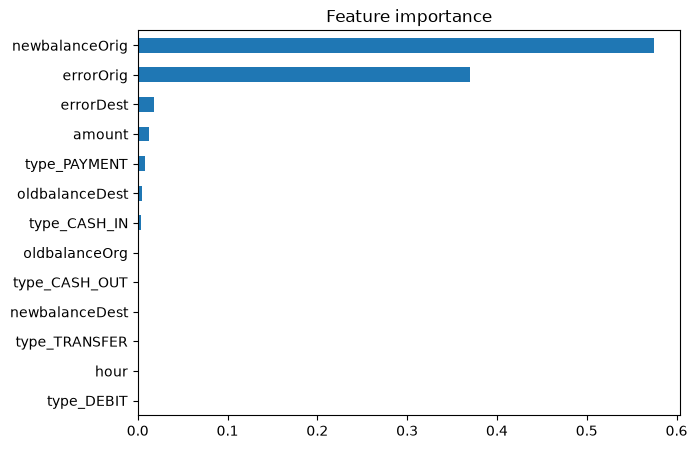

In [12]:
from sklearn.metrics import confusion_matrix

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_test, xgb_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Legit", "Pred Fraud"],
            yticklabels=["Actual Legit", "Actual Fraud"])
plt.title("XGBoost confusion matrix")
plt.show()

# Which columns did the model rely on most?
importances = pd.Series(xgb.feature_importances_, index=X_train.columns)
importances.sort_values().plot(kind="barh", figsize=(7, 5), title="Feature importance")
plt.show()

In [13]:
# Train ONLY on legit transactions, so it learns what "normal" looks like.
# It never sees a fraud label.
X_train_legit = X_train[y_train == 0]

iso = IsolationForest(
    n_estimators=200,
    contamination=0.05,   # rough guess of the fraction of anomalies
    random_state=42,
)
iso.fit(X_train_legit)

# decision_function: LOWER = more anomalous.
# We flip the sign so that HIGHER = more suspicious, to match XGBoost's probability.
iso_scores = -iso.decision_function(X_test)

# Rescale to 0-1 so it's easy to combine with XGBoost later
iso_scores = (iso_scores - iso_scores.min()) / (iso_scores.max() - iso_scores.min())

# Quick check: how well do these anomaly scores separate fraud from legit?
from sklearn.metrics import average_precision_score
print("XGBoost PR-AUC:         ", round(average_precision_score(y_test, xgb_probs), 3))
print("Isolation Forest PR-AUC:", round(average_precision_score(y_test, iso_scores), 3))

XGBoost PR-AUC:          0.999
Isolation Forest PR-AUC: 0.3


Combined PR-AUC: 0.999


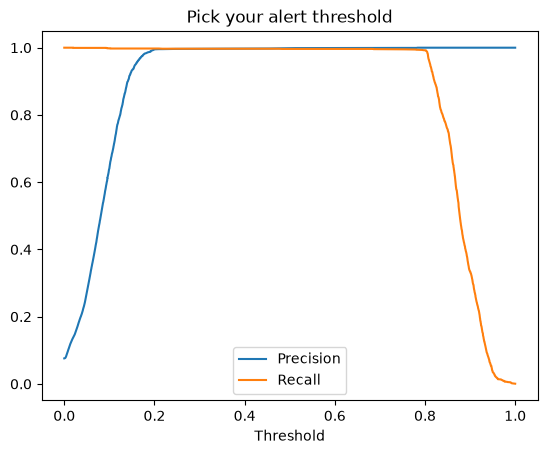

In [14]:
# Weighted blend: trust XGBoost more, let Isolation Forest add a "weirdness" signal
final_score = 0.8 * xgb_probs + 0.2 * iso_scores
print("Combined PR-AUC:", round(average_precision_score(y_test, final_score), 3))

# Instead of the default 0.5, look at precision and recall at every threshold
precision, recall, thresholds = precision_recall_curve(y_test, final_score)
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.xlabel("Threshold"); plt.legend(); plt.title("Pick your alert threshold")
plt.show()

In [15]:
# Estimate precision if fraud were as rare as in the full dataset.
# Use the numbers YOU printed from df["isFraud"].value_counts() in Cell 2
# (PaySim is roughly 8,213 fraud and 6,354,407 legit; replace if yours differ).
natural_fraud = 8213
natural_legit = 6354407

# Rates measured on your test set
tp, fp, fn = 1637, 4, 6
tn = 19996
tpr = tp / (tp + fn)          # recall: fraction of frauds caught
fpr = fp / (fp + tn)          # false-alarm rate: fraction of legit flagged

# Scale to the natural ratio
caught = tpr * natural_fraud          # frauds caught in the full data
false_alarms = fpr * natural_legit    # legit payments wrongly flagged

print("Frauds caught:", round(caught))
print("False alarms:", round(false_alarms))
print("Precision at natural ratio:", round(caught / (caught + false_alarms), 3))

Frauds caught: 8183
False alarms: 1271
Precision at natural ratio: 0.866


c:\Users\gayat\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


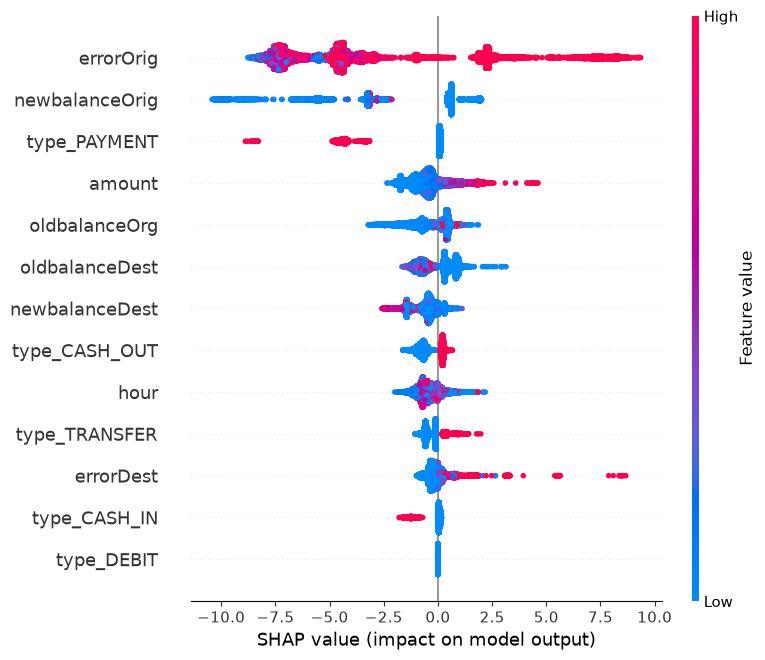

Risk score: 1.0
 - Sender's balance doesn't add up after this payment
 - Sender's balance after this payment is unusual (e.g. account emptied)
 - Payment amount is unusual


In [16]:
import shap

# TreeExplainer is built for tree models like XGBoost; it's fast
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)   # one SHAP value per feature per row

# Global view: which features push predictions toward fraud, across all rows
shap.summary_plot(shap_values, X_test)

# Plain-English phrase for each feature (only features the model really uses)
REASONS = {
    "newbalanceOrig": "Sender's balance after this payment is unusual (e.g. account emptied)",
    "errorOrig":      "Sender's balance doesn't add up after this payment",
    "errorDest":      "Receiver's balance change doesn't match the amount sent",
    "amount":         "Payment amount is unusual",
    "oldbalanceDest": "Receiver account's balance looks unusual",
    "type_PAYMENT":   "Payment type is unusual for this pattern",
    "type_CASH_IN":   "Payment type is unusual for this pattern",
}

def explain_row(i, top_n=3):
    """Return the top reasons a transaction (row i of X_test) looks risky."""
    contribs = pd.Series(shap_values[i], index=X_test.columns)
    # Positive SHAP value = pushed the score TOWARD fraud
    top = contribs[contribs > 0].sort_values(ascending=False).head(top_n)
    return [REASONS.get(feat, feat) for feat in top.index]

# Try it on a transaction the model flagged as fraud
fraud_idx = np.where(xgb_preds == 1)[0][0]
print("Risk score:", round(float(xgb_probs[fraud_idx]), 3))
for reason in explain_row(fraud_idx):
    print(" -", reason)

In [ ]:
# Plain-English reasons, only for features that can push a score TOWARD fraud
REASONS = {
    "errorOrig":      "Sender's balance doesn't add up after this payment",
    "errorDest":      "Receiver's balance change doesn't match the amount sent",
    "amount":         "Payment amount is unusually large",
    "newbalanceOrig": "Sender's account is left with a zero or near-zero balance",
    "oldbalanceOrg":  "Sender's starting balance looks unusual for this payment",
    "oldbalanceDest": "Receiver account's balance looks unusual",
    "newbalanceDest": "Receiver's balance after payment looks unusual",
    "type_TRANSFER":  "Transfers to other accounts carry higher risk",
    "type_CASH_OUT":  "Cash-out payments carry higher risk",
    "hour":           "Payment made at an unusual time of day",
}

In [17]:
# What fraction of each class has newbalanceOrig == 0?
# (rebuild from your current df, which still has the isFraud column)
print(df.groupby("isFraud")["newbalanceOrig"].apply(lambda s: (s == 0).mean()))

isFraud
0    0.569310
1    0.980519
Name: newbalanceOrig, dtype: float64


In [18]:
import joblib

# Isolation Forest is a scikit-learn model, so we save it with joblib
joblib.dump(iso, "iso_model.pkl")

# Also save the min and max of its raw scores. In the notebook we rescaled scores
# to 0-1 using the test set's min and max; without these two numbers you couldn't
# reproduce that scaling later.
raw = -iso.decision_function(X_test)
joblib.dump({"min": float(raw.min()), "max": float(raw.max())}, "iso_scaling.pkl")

print("Saved: iso_model.pkl, iso_scaling.pkl")

Saved: iso_model.pkl, iso_scaling.pkl


In [19]:
iso_check = joblib.load("iso_model.pkl")
same = np.allclose(-iso_check.decision_function(X_test), raw)
print("Reloaded Isolation Forest matches original:", same)   # should print True

Reloaded Isolation Forest matches original: True


In [20]:
import json

# 1. Save the model in XGBoost's own JSON format.
#    This is safer than pickle because it doesn't break if library versions differ slightly.
xgb.save_model("xgb_model.json")

# 2. Save the exact column order. The API MUST feed columns in this order,
#    or the model will silently give wrong scores.
with open("feature_columns.json", "w") as f:
    json.dump(list(X_train.columns), f)

# 3. Save the settings the API needs: alert threshold and plain-English reasons
config = {
    "threshold": 0.5,   # score at or above this = RISKY (we can tune it later)
    "reasons": REASONS, # your plain-English feature descriptions from the SHAP step
}
with open("config.json", "w") as f:
    json.dump(config, f, indent=2)

# 4. Save the held-out rows. The stream simulator replays these as "live" payments.
X_test.assign(isFraud=y_test.values).to_csv("test_stream.csv", index=False)

print("Saved: xgb_model.json, feature_columns.json, config.json, test_stream.csv")

Saved: xgb_model.json, feature_columns.json, config.json, test_stream.csv


In [21]:
# Load the saved model into a fresh object and confirm it gives the same scores
check = XGBClassifier()
check.load_model("xgb_model.json")

same = np.allclose(check.predict_proba(X_test)[:, 1], xgb_probs)
print("Reloaded model matches original:", same)   # should print True

Reloaded model matches original: True
